# VIS4AI · Notebook 02 — Plot results (without the support of AI)

Goal of this notebook: load the results from Notebook 01 and visualize the experiment results using matplotlib and seaborn. On Colab, results are read from Google Drive; locally, they are read from the repository's `data/<run>` folder. This notebook has been written without the help of agents/llms.

In [3]:
import ast
import pandas as pd
import seaborn as sns
import os
import matplotlib.pyplot as plt
import re
import numpy as np
from pathlib import Path

RUN = ""

try:                               # on Colab: read from Google Drive
    from google.colab import drive
    drive.mount("/content/drive")
    RESULTS_DIR = Path("/content/drive/MyDrive/VIS4AI/results") / RUN
except ImportError:                # locally: read from data/ in the repo
    data_dir = Path.cwd().parent / "data" if Path.cwd().name == "notebooks" else Path.cwd() / "data"
    RESULTS_DIR = next(p for p in [data_dir / RUN, data_dir / RUN.split("_2")[0]] if p.exists())
print("Reading results from:", RESULTS_DIR)

# Load the data from the results folder
result_folder = RESULTS_DIR

results_files = [f for f in os.listdir(result_folder) if f.endswith('.jsonl')]
parameters_files = [f for f in os.listdir(result_folder) if f.endswith('.txt')]

dfs = []
for file in results_files:
    data_path = os.path.join(result_folder, file)
    df = pd.read_json(data_path, lines=True)
    dfs.append(df)

# Concatenate all dataframes into a single dataframe
combined_df = pd.concat(dfs, ignore_index=True)

# Load parameters from text files
parameters = []
for file in parameters_files:
    param_path = os.path.join(result_folder, file)
    data_dict = {}
    with open(param_path, "r") as file:
        for line in file:
            # Strip whitespace/newlines and split by the delimiter
            if ":" in line:
                key, value = line.strip().split(":", 1)
                data_dict[key.strip()] = value.strip()

    print(data_dict)
    parameters.append(data_dict)

models = ast.literal_eval(parameters[0]['models'])
max_tokens = {cfg['name']: cfg['max_new_tokens'] for cfg in models.values()}

# New features
combined_df['words_in'] = combined_df['question'].apply(lambda x: len(x.split()))
combined_df['words_out'] = combined_df['output'].apply(lambda x: len(x.split()))
combined_df['numbers_out'] = combined_df['output'].apply(lambda x: len(re.findall(r'\d+', x)))
combined_df['model_short'] = combined_df["model"].str.split("/").str[-1]
combined_df['max_tokens'] = combined_df['model'].map(max_tokens)
combined_df['temperature'] = float(parameters[0]['temperature'])
combined_df['top_p'] = float(parameters[0]['top_p'])
combined_df['batch_size'] = int(parameters[0]['batch_size'])

combined_df

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Reading results from: /content/drive/MyDrive/VIS4AI/results
{'run': 'run_1_2026-11-10_13-09', 'written': '2026-11-10 13:09:17', 'models': "{'r1-distill': {'name': 'deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B', 'thinks': True, 'chat_template': True, 'sampling': True, 'max_new_tokens': 8192, 'stop_after_answer': False}, 'qwen-math': {'name': 'Qwen/Qwen2.5-Math-1.5B', 'thinks': False, 'chat_template': False, 'sampling': False, 'max_new_tokens': 2048, 'stop_after_answer': True}}", 'n_problems': '50', 'batch_size': '12', 'temperature': '0.6', 'top_p': '0.95', 'seed': '42', 'instruction': 'Please reason step by step, and put your final answer within \\boxed{}.', 'gpu': 'Tesla T4', 'torch': '2.14.1+cu130', 'transformers': '5.22.1'}


,id,question,gold,model,output,answer,correct,n_tokens,finished,batch_time,answer_time,chain_of_thought_length,words_in,words_out,numbers_out,model_short,max_tokens,temperature,top_p,batch_size
0,0,Janet’s ducks lay 16 eggs per day. She eats th...,18,Qwen/Qwen2.5-Math-1.5B,To determine how much Janet makes every day at...,18,True,385,True,32.452258,18.034103,8,52,266,33,Qwen2.5-Math-1.5B,2048,0.6,0.95,12
1,1,A robe takes 2 bolts of blue fiber and half th...,3,Qwen/Qwen2.5-Math-1.5B,"To solve this problem, we need to determine th...",3,True,193,True,32.452258,10.017806,4,22,140,8,Qwen2.5-Math-1.5B,2048,0.6,0.95,12
2,2,Josh decides to try flipping a house. He buys...,70000,Qwen/Qwen2.5-Math-1.5B,"To determine the profit Josh made, we need to ...",70000,True,389,True,32.452258,18.263052,9,35,214,45,Qwen2.5-Math-1.5B,2048,0.6,0.95,12
3,3,James decides to run 3 sprints 3 times a week....,540,Qwen/Qwen2.5-Math-1.5B,To determine the total number of meters James ...,180,False,157,True,32.452258,8.593148,4,25,101,6,Qwen2.5-Math-1.5B,2048,0.6,0.95,12
4,4,"Every day, Wendi feeds each of her chickens th...",20,Qwen/Qwen2.5-Math-1.5B,To determine how many cups of feed Wendi needs...,140,False,411,True,32.452258,19.418246,6,87,243,28,Qwen2.5-Math-1.5B,2048,0.6,0.95,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,45,Meredith is a freelance blogger who writes abo...,104,deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B,"Okay, let me try to figure out how many hours ...",104,True,1019,True,681.381595,58.633022,28,79,624,141,DeepSeek-R1-Distill-Qwen-1.5B,8192,0.6,0.95,12
96,46,Candice put 80 post-it notes in her purse befo...,163,deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B,"Okay, so Candice starts with 80 post-it notes ...",163,True,2014,True,681.381595,137.904922,71,70,1210,185,DeepSeek-R1-Distill-Qwen-1.5B,8192,0.6,0.95,12
97,47,John buys twice as many red ties as blue ties....,800,deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B,"Alright, let me try to figure out this problem...",800,True,1085,True,681.381595,62.787040,29,36,695,106,DeepSeek-R1-Distill-Qwen-1.5B,8192,0.6,0.95,12
98,48,Tracy used a piece of wire 4 feet long to supp...,8,deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B,"Okay, so Tracy has a piece of wire that's 4 fe...",8,True,1118,True,49.591324,49.584850,23,31,799,89,DeepSeek-R1-Distill-Qwen-1.5B,8192,0.6,0.95,12


## Group by model

In [4]:

df_grouped = combined_df.groupby("model_short").agg(
                                    accuracy=("correct", "mean"),
                                    cut_off=("finished", lambda s: 1 - s.mean()),
                                    no_answer=("answer", lambda s: s.isna().mean()),
                                    mean_tokens=("n_tokens", "mean"),
                                    mean_chain_of_tought_length=("chain_of_thought_length", "mean"),
                                    mean_words_out=('words_out', 'mean'),
                                    mean_answer_time=('answer_time', 'mean'),
                                    mean_numbers_out=('numbers_out', 'mean'),
                                    max_tokens=('max_tokens', 'mean'),
                                    top_p=('top_p', 'mean'),
                                    temperature=('temperature', 'mean'),
                                    batch_size=('batch_size', 'mean')
                                    ).reset_index()

rates = df_grouped.melt(id_vars="model_short", value_vars=["accuracy", "cut_off", "no_answer"],
                        var_name="metric", value_name="rate")

df_grouped

,model_short,accuracy,cut_off,no_answer,mean_tokens,mean_chain_of_tought_length,mean_words_out,mean_answer_time,mean_numbers_out,max_tokens,top_p,temperature,batch_size
0,DeepSeek-R1-Distill-Qwen-1.5B,0.86,0.06,0.06,2344.60,59.26,1477.98,241.399821,238.74,8192.0,0.95,0.6,12.0
1,Qwen2.5-Math-1.5B,0.80,0.04,0.04,420.86,6.84,259.80,20.785271,33.60,2048.0,0.95,0.6,12.0


## Plotting functions

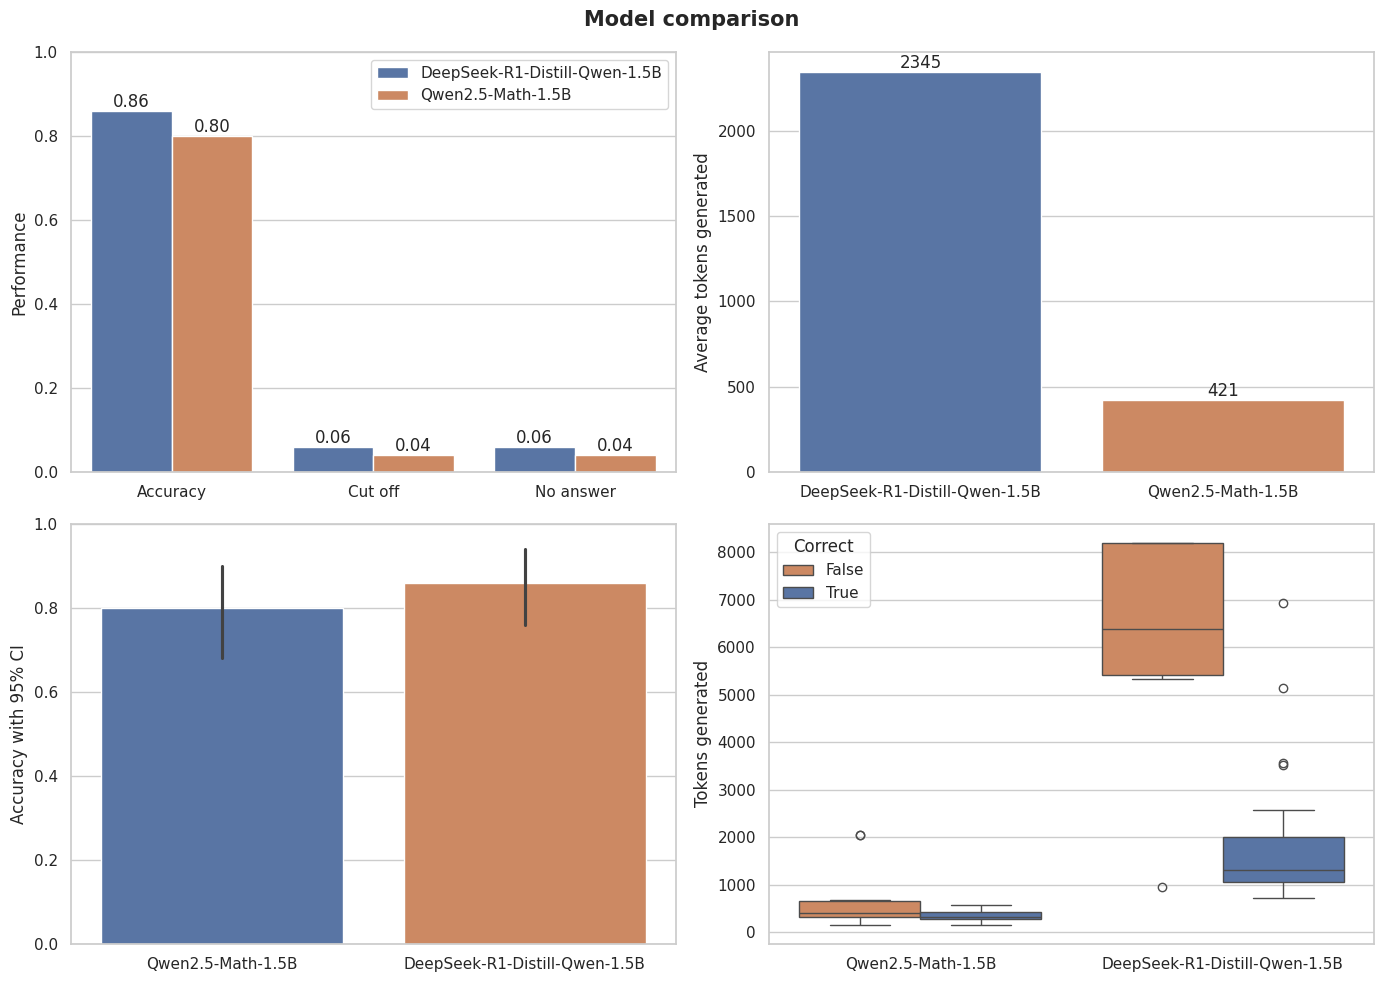

In [6]:
sns.set_theme(style="whitegrid", context="notebook")
palette = {True: "#4C72B0", False: "#DD8452"}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Performance summary
ax = axes[0, 0]
sns.barplot(data=rates, x="metric", y="rate", hue="model_short", ax=ax)
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f")
ax.set(ylim=(0, 1), xlabel="", ylabel="Performance")
ax.set_xticks(ax.get_xticks(), ["Accuracy", "Cut off", "No answer"])

ax.legend(title="")

# Output length
ax = axes[0, 1]
sns.barplot(data=df_grouped, x="model_short", y="mean_tokens", hue="model_short", ax=ax)
ax.bar_label(ax.containers[0], fmt="%.0f")
ax.bar_label(ax.containers[1], fmt="%.0f")
ax.set(xlabel="", ylabel="Average tokens generated")

# Accuracy with confidence interval
ax = axes[1, 0]
sns.barplot(data=combined_df, x="model_short", y="correct", hue="model_short", errorbar=("ci", 95), ax=ax)
ax.set(ylim=(0, 1), xlabel="", ylabel="Accuracy with 95% CI")

# Output length by correctness
ax = axes[1, 1]
sns.boxplot(data=combined_df, x="model_short", y="n_tokens", hue="correct", palette=palette, ax=ax)
ax.set(xlabel="", ylabel="Tokens generated")
ax.legend(title="Correct")

fig.suptitle("Model comparison", size=15, weight="bold")
plt.tight_layout()
plt.show()


### Model Comparison
Deepseek answered 43 out of 50 problems correctly (86%), whereas Qwen had 40 correctly answered (80%). The difference is 6% among these models.

However, Deepseek generated about 2.3k tokens that is approximately 5.6 times more and had an average answer time approximately 11.6 times higher than Qwen. This shows that there is a tradeoff between observed accuracy and generaton cost( token generation).

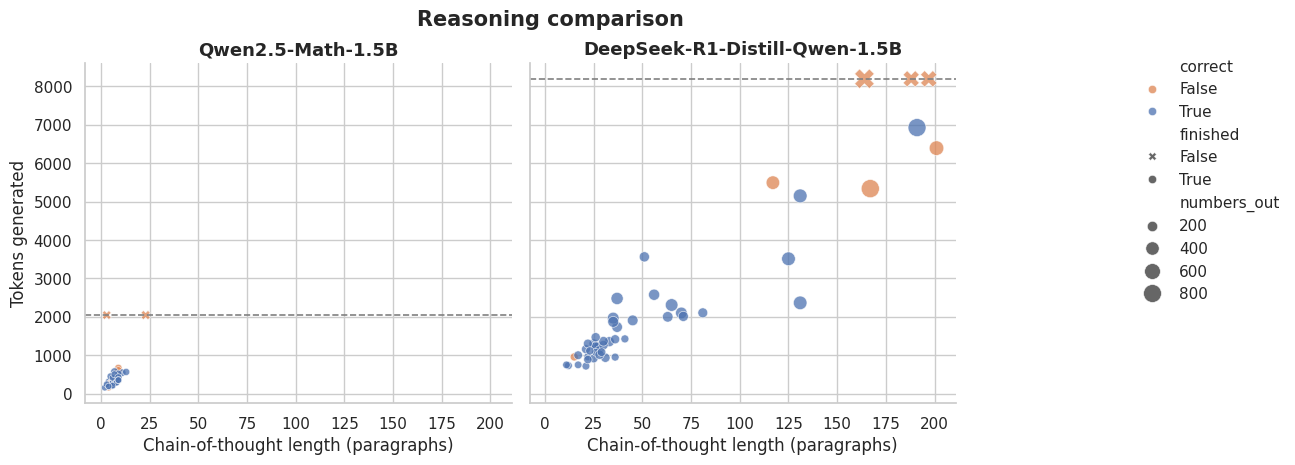

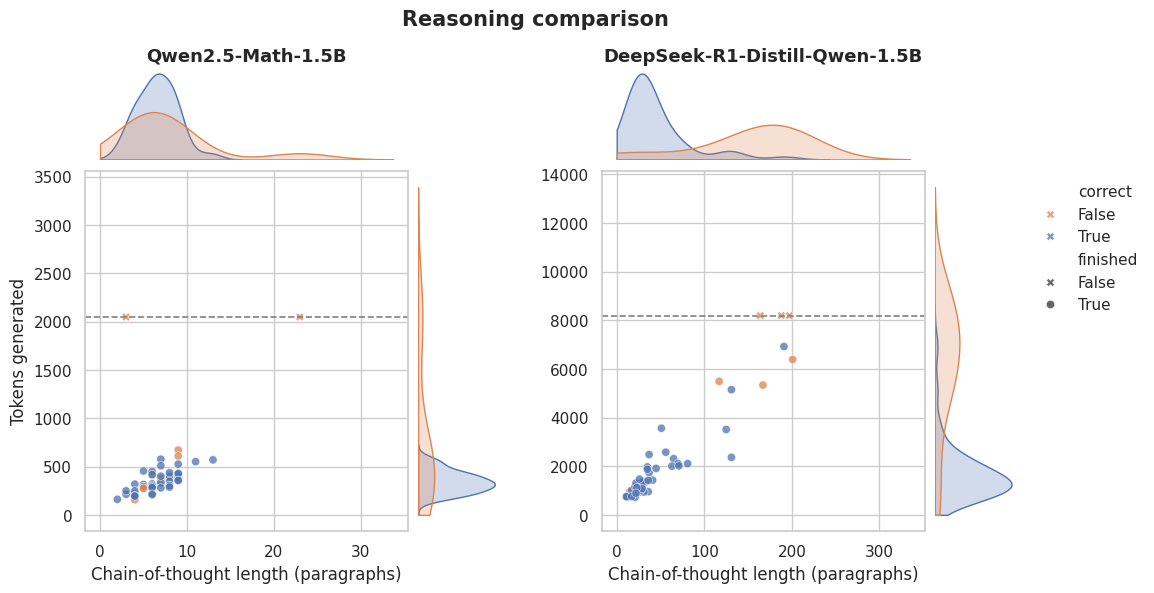

In [7]:
# Relplot
g = sns.relplot(
    data=combined_df, x="chain_of_thought_length", y="n_tokens", col="model_short",
    hue="correct", size="numbers_out", style="finished",
    palette=palette, sizes=(20, 200),
    markers={True: "o", False: "X"}, alpha=0.75, edgecolor="white", linewidth=0.5,
    height=4.5, aspect=1.1,
)

lines = {
    "DeepSeek-R1-Distill-Qwen-1.5B": int(df_grouped[df_grouped["model_short"] == "DeepSeek-R1-Distill-Qwen-1.5B"]["max_tokens"].iloc[0]),
    "Qwen2.5-Math-1.5B": int(df_grouped[df_grouped["model_short"] == "Qwen2.5-Math-1.5B"]["max_tokens"].iloc[0])
    }

for model, ax in g.axes_dict.items():
    ax.axhline(lines[model], color="gray", linestyle="--", linewidth=1.2)

g.set_titles("{col_name}", size=13, weight="bold")
g.set_axis_labels("Chain-of-thought length (paragraphs)", "Tokens generated")
g.figure.suptitle("Reasoning comparison", y=1.03, size=15, weight="bold")
sns.move_legend(g, "upper left", bbox_to_anchor=(1, 0.95), frameon=False)
plt.show()

# JointGrid for each model
models = combined_df["model_short"].unique()
x, y = "chain_of_thought_length", "n_tokens"

fig = plt.figure(figsize=(6 * len(models), 6))
outer = fig.add_gridspec(1, len(models), wspace=0.25)

for k, model in enumerate(models):
    d = combined_df[combined_df["model_short"] == model]
    inner = outer[k].subgridspec(2, 2, width_ratios=(4, 1), height_ratios=(1, 4), hspace=0.05, wspace=0.05)
    ax       = fig.add_subplot(inner[1, 0])
    ax_top   = fig.add_subplot(inner[0, 0], sharex=ax)
    ax_right = fig.add_subplot(inner[1, 1], sharey=ax)

    sns.scatterplot(data=d, x=x, y=y, hue="correct", style="finished", markers={True: "o", False: "X"},
                    palette=palette, alpha=0.75, edgecolor="white", ax=ax, legend=(k == len(models) - 1))
    sns.kdeplot(data=d, x=x, hue="correct", palette=palette, fill=True, common_norm=False,
                clip=(0, None), warn_singular=False, legend=False, ax=ax_top)
    sns.kdeplot(data=d, y=y, hue="correct", palette=palette, fill=True, common_norm=False,
                clip=(0, None), warn_singular=False, legend=False, ax=ax_right)

    ax.axhline(lines[model], color="gray", linestyle="--", linewidth=1.2)
    ax.set(xlabel="Chain-of-thought length (paragraphs)", ylabel="Tokens generated" if k == 0 else "")
    ax_top.set_title(model, size=13, weight="bold")
    ax_top.axis("off")
    ax_right.axis("off")

sns.move_legend(ax, "upper left", bbox_to_anchor=(1.3, 1), frameon=False)
fig.suptitle("Reasoning comparison", size=15, weight="bold")
plt.show()


Interpretation:
 - Most of the NOK results comes from a hitting the token limit!
 - The reasoning model (DeepSeek R1) used more tokens and built a longer chain of tought to get an answer, but it also brought a higher number of correct answers

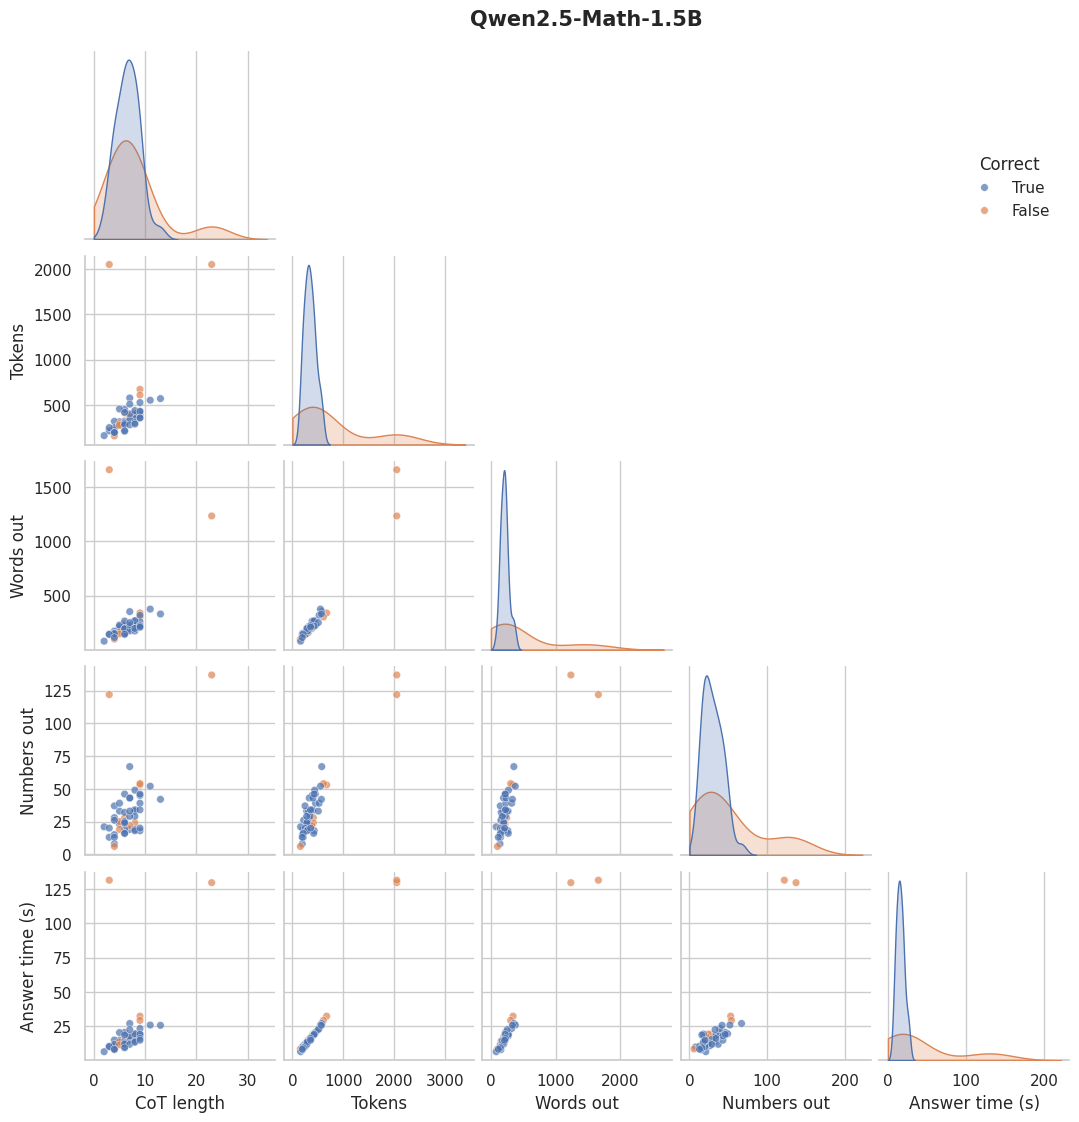

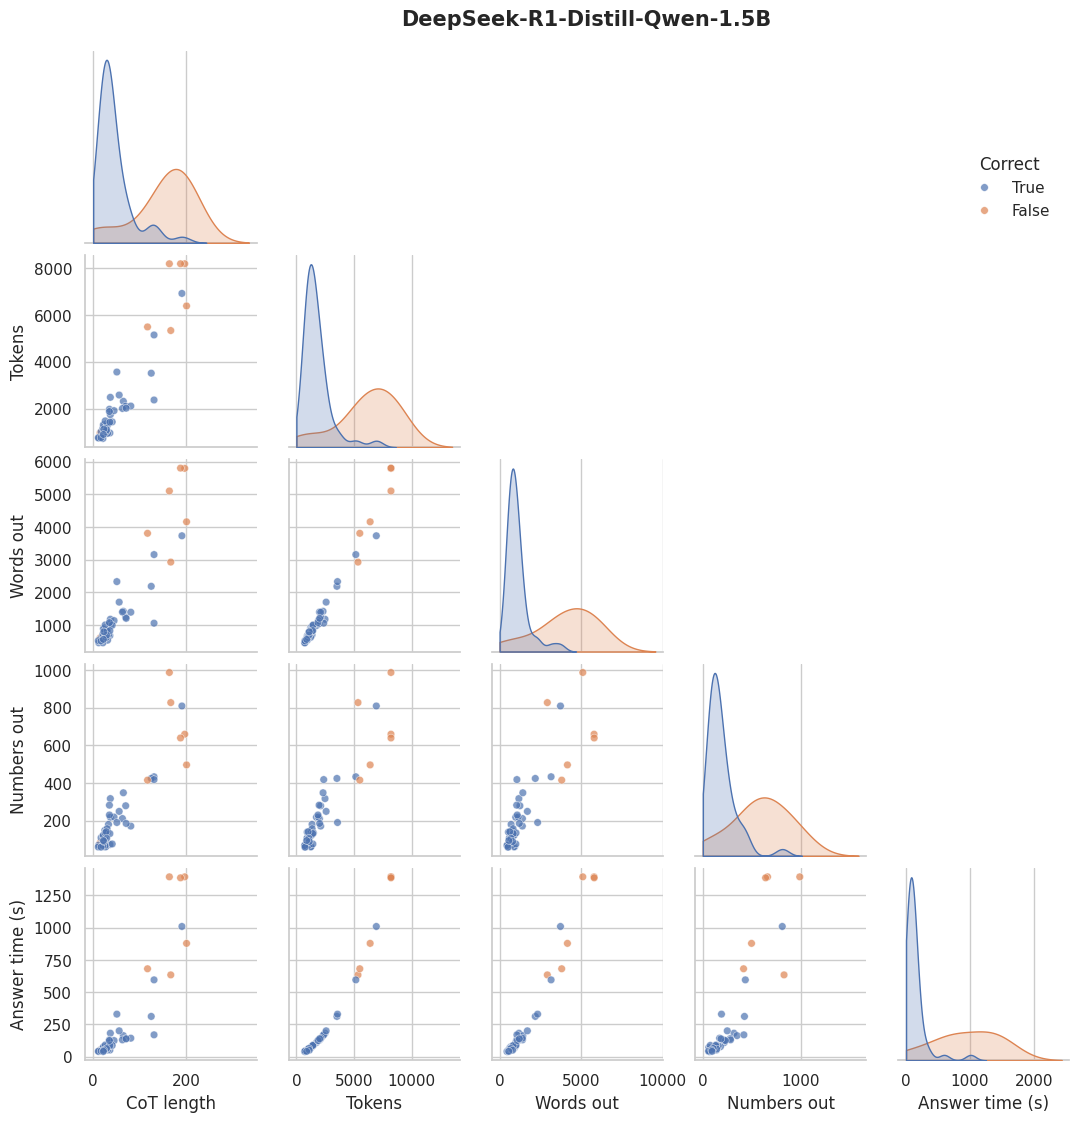

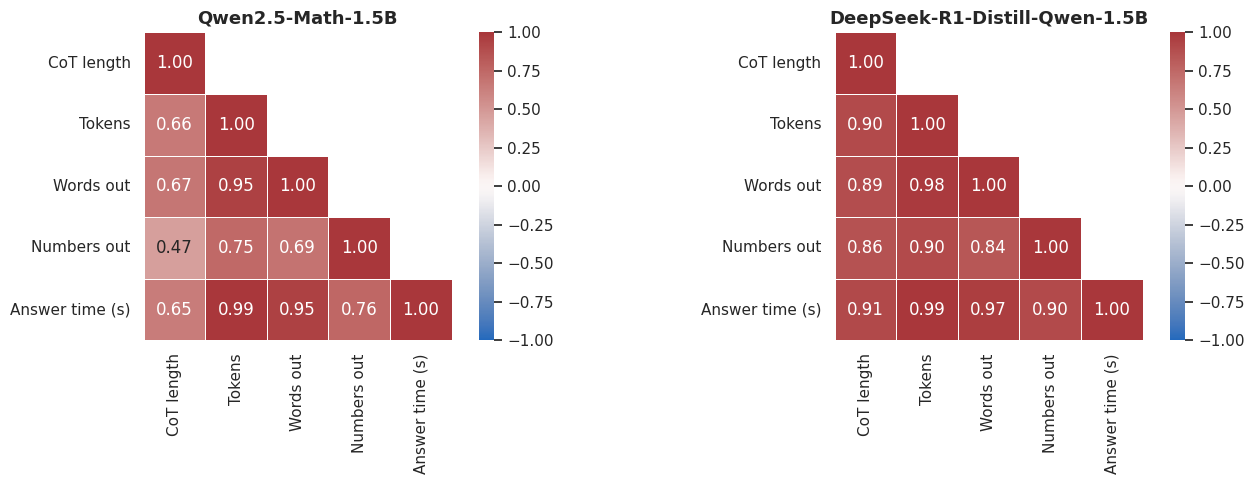

In [8]:
# Pairplot
cols = {"chain_of_thought_length": "CoT length", "n_tokens": "Tokens",
        "words_out": "Words out", "numbers_out": "Numbers out", "answer_time": "Answer time (s)"}

for model in combined_df["model_short"].unique():
    d = combined_df[combined_df["model_short"] == model].rename(columns=cols)

    g = sns.pairplot(d, vars=list(cols.values()), hue="correct", palette=palette, hue_order=[True, False],
                     corner=True, height=2.2, diag_kind="kde",
                     plot_kws={"alpha": 0.7, "s": 30, "edgecolor": "white", "linewidth": 0.4},
                     diag_kws={"fill": True, "common_norm": False, "clip": (0, None), "warn_singular": False})
    g.figure.suptitle(model, size=15, weight="bold", y=1.02)
    sns.move_legend(g, "upper right", bbox_to_anchor=(0.9, 0.9), title="Correct", frameon=False)
    plt.show()

# Correlation heatmaps
models = combined_df["model_short"].unique()
fig, axes = plt.subplots(1, len(models), figsize=(14, 5))

for ax, model in zip(axes, models):
    model_df = combined_df[combined_df["model_short"] == model]
    corr = model_df[list(cols)].corr(method="spearman").rename(columns=cols, index=cols)
    matrix = np.triu(corr) - np.eye(corr.shape[0], dtype=bool)

    sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, ax=ax, mask=matrix, square=True, linewidths=0.5)
    ax.set_title(model, size=13, weight="bold")
    ax.grid(False)

plt.tight_layout()
plt.show()


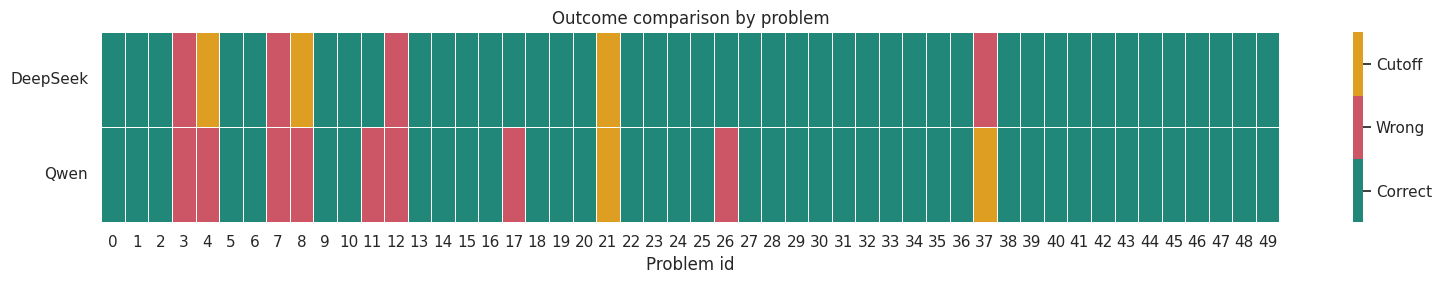

In [12]:
from matplotlib.colors import ListedColormap

# 0 = correct, 1 = finished but wrong, 2 = cutoff
conditions = [
    combined_df["finished"] == False,
    combined_df["correct"] == True
]
choices = [ 2, 0 ]
d = combined_df.assign(outcome=np.select(conditions, choices, default=1))

matrix = d.pivot(
    index="model_short", columns="id", values="outcome"
).sort_index(axis=1)

fig, ax = plt.subplots(figsize=(16, 3))

sns.heatmap(
    matrix,
    cmap=ListedColormap(["#218778", "#CC5665", "#DE9E22"]),
    vmin=-0.5, vmax=2.5,
    linewidths=0.5, linecolor="white",
    xticklabels=True, yticklabels=True,
    cbar_kws={"ticks": [0, 1, 2]},
    ax=ax
)

colorbar = ax.collections[0].colorbar
colorbar.set_ticklabels(["Correct", "Wrong", "Cutoff"])

ax.set(
    title="Outcome comparison by problem",
    xlabel="Problem id",
    ylabel=""
)
ax.set_yticklabels(["DeepSeek", "Qwen"], rotation=0)

plt.tight_layout()
plt.show()

A direct comparison is done for both models where each column represents the same problems given. Green indicates a correct response given, red a finished but incorrect response, and yellow a cutoff.

The probelm 11, 17 and 26 were correctly answered by Deepseek while Qwen failed. Neither model succeeded on problems 3, 4, 7, 8, 12, 21 and 37.


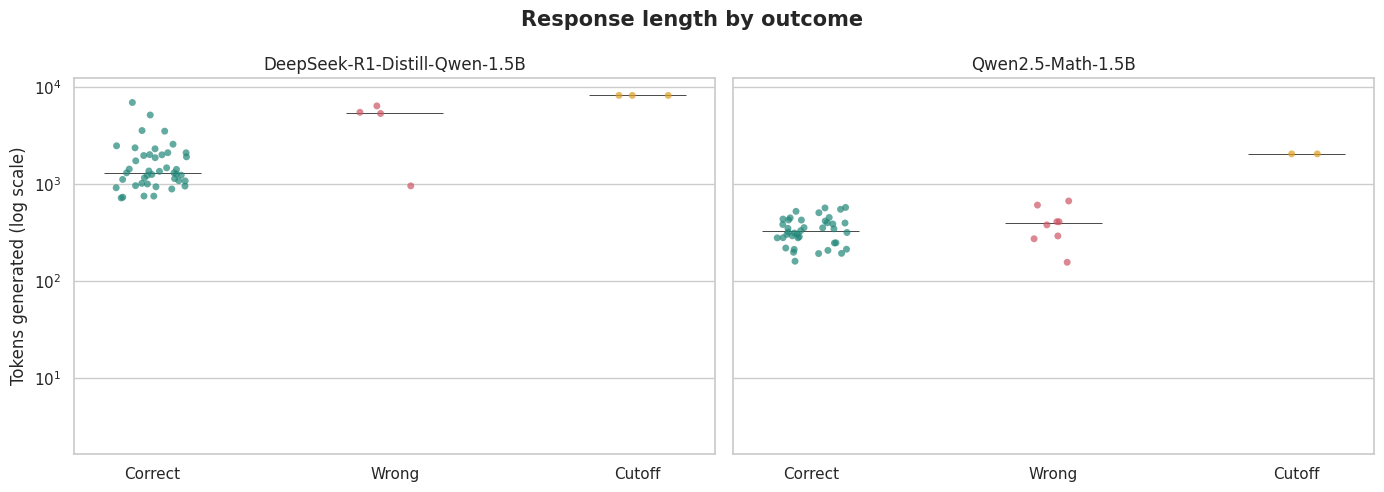

In [18]:
conditions = [
    combined_df["finished"] == False,
    combined_df["correct"] == True
]
choices = ["Cutoff","Correct"]


d = combined_df.assign(outcome=np.select(conditions, choices, default="Wrong"))

models = sorted(d["model_short"].unique())
fig, axes = plt.subplots(1, len(models), figsize=(14, 5), sharey=True)

for ax, model in zip(axes, models):
    model_df = d[d["model_short"] == model]

    sns.stripplot(
        data=model_df,
        x="outcome", y="n_tokens",
        order=["Correct", "Wrong", "Cutoff"],
        hue="outcome",
        palette={
            "Correct": "#218778",
            "Wrong": "#CC5665",
            "Cutoff": "#DE9E22"
        },
        jitter=0.15, alpha=0.7, legend=False, ax=ax
    )

    # Black line marking the median
    for position, outcome in enumerate(["Correct", "Wrong", "Cutoff"]):
        values = model_df.loc[
            model_df["outcome"] == outcome, "n_tokens"
        ]

        if not values.empty:
            ax.hlines(
                values.median(),
                position - 0.2, position + 0.2,
                color="black", linewidth=0.5
            )

    ax.set_yscale("log")
    ax.set(
        title=model,
        xlabel="",
        ylabel="Tokens generated (log scale)"
    )

fig.suptitle("Response length by outcome", size=15, weight="bold")
plt.tight_layout()
plt.show()

Each dot represents one response given by models, and the back line shows the median token count. The y-axis uses log scale, thus giving equal distances that respresent multiplicative changes in response length.


*   DeepSeek’s finished but incorrect responses generally used more tokens than its correct responses, although the groups overlap
*   Qwen’s correct and incorrect responses also overlap substantially.
* Cutoff responses cluster near to token limit for each model.

From these patterns it can be taken that length of responses alone is not sufficient to predict correctness of model.




